# Практика 4. Проверка модели и диагностика новых сигналов — Python

В семинаре 3 обучили три случайных леса. Теперь превратим их в конвейер
принятия решений: загрузка модели → те же 54 признака → нормализация →
прогноз по окнам → итоговое инженерное решение.

шкала 0–100 в этой учебной модели — это оценка mixing coefficient
(коэффициента смешивания) эталонных сигналов, а не измеренный физический
процент износа. Перед промышленным применением нужны независимые данные и калибровка.

## 1. Библиотеки и пути

`joblib` загружает сохранённый комплект. Файлы pickle/joblib могут выполнять код:
загружайте их только из доверенного источника.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.io import loadmat, wavfile
from scipy.signal import hilbert
from scipy.stats import skew, kurtosis

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True})

DATA = Path("data_seminar")
MODEL_PATH = DATA / "bearing_models_python.joblib"

## 2. Загрузка всего конвейера

Одних моделей недостаточно. Нужны также масштабировщик, порядок признаков,
частота дискретизации и параметры окна. Всё это хранится в одном bundle.

In [2]:
bundle = joblib.load(MODEL_PATH)
models = bundle["models"]
scaler = bundle["scaler"]
feature_names = bundle["feature_names"]
FS = bundle["fs"]
SEGMENT_LEN = bundle["segment_length"]
OVERLAP = bundle["overlap"]
LABEL_ORDER = bundle["label_order"]

summary = pd.Series({
    "моделей": len(models), "признаков": len(feature_names),
    "частота, Гц": FS, "длина окна": SEGMENT_LEN, "перекрытие": OVERLAP,
})
display(summary.to_frame("значение"))
assert len(models) == 3 and len(feature_names) == 54

,значение
моделей,3.00
признаков,54.00
"частота, Гц",10000.00
длина окна,4000.00
перекрытие,0.75


## 3. Тот же расчёт 54 признаков

Функция должна быть идентична функции на обучении: те же формулы, порядок и единицы.

In [3]:
FEATURE_NAMES = [
    "mean", "median", "rms", "std", "variance", "maximum", "minimum", "range",
    "skewness", "kurtosis", "crest_ratio", "impulse_ratio", "shape_ratio", "time_energy",
    "spectral_max", "dominant_frequency", "spectral_centroid", "spectral_width",
    "spectral_entropy", "spectral_flatness", "mean_frequency", "median_frequency",
    "rolloff_85", "spectral_energy", "spectral_std", "spectral_skewness",
    "spectral_kurtosis",
    *[f"band_{low}_{low + 500}" for low in range(0, 5000, 500)],
    "envelope_spectral_max", "envelope_frequency", "envelope_spectral_energy",
    "envelope_entropy", "envelope_centroid", "envelope_mean", "envelope_std",
    "envelope_max", "envelope_kurtosis", "zero_crossing_rate", "high_mid_low_ratio",
    "envelope_energy_ratio", "absolute_crest_ratio", "fraction_below_q25",
    "small_to_large_amplitude", "small_to_large_energy", "q75_to_q25",
]


def extract_features(signal, fs=10_000):
    """54 time, spectrum and envelope features; one row per 0.4 s window."""
    x = np.asarray(signal, dtype=float)
    centered = x - x.mean()
    absolute = np.abs(centered)
    rms = np.sqrt(np.mean(centered ** 2))
    abs_mean = absolute.mean()
    eps = 1e-10

    time_features = [
        x.mean(), np.median(x), rms, centered.std(ddof=1),
        centered.var(ddof=1), x.max(), x.min(), np.ptp(x),
        skew(centered), kurtosis(centered), x.max() / (rms + eps),
        x.max() / (abs_mean + eps), rms / (abs_mean + eps),
        np.sum(centered ** 2),
    ]

    amplitude = np.abs(np.fft.rfft(centered))[:-1]  # exclude the Nyquist bin as in source
    frequency = np.fft.rfftfreq(len(x), d=1 / fs)[:-1]
    weights = amplitude / (amplitude.sum() + eps)
    cumulative = np.cumsum(weights)
    centroid = np.sum(frequency * weights)
    positive = weights[weights > 0]
    flatness = np.exp(np.mean(np.log(positive))) / (weights.mean() + eps)
    spectral_features = [
        amplitude.max(), frequency[np.argmax(amplitude)], centroid,
        np.sqrt(np.sum((frequency - centroid) ** 2 * weights)),
        -np.sum(positive * np.log(positive)), flatness, centroid,
        frequency[min(np.searchsorted(cumulative, 0.5), len(frequency) - 1)],
        frequency[min(np.searchsorted(cumulative, 0.85), len(frequency) - 1)],
        np.sum(amplitude ** 2), amplitude.std(ddof=1),
        skew(amplitude), kurtosis(amplitude),
    ]

    band_energy = np.array([
        np.sum(amplitude[(frequency >= low) & (frequency < low + 500)] ** 2)
        for low in range(0, 5000, 500)
    ])

    envelope = np.abs(hilbert(centered))
    env_amplitude = np.abs(np.fft.rfft(envelope - envelope.mean()))[:-1]
    env_weights = env_amplitude / (env_amplitude.sum() + eps)
    env_positive = env_weights[env_weights > 0]
    envelope_features = [
        env_amplitude.max(), frequency[np.argmax(env_amplitude)],
        np.sum(env_amplitude ** 2),
        -np.sum(env_positive * np.log(env_positive)),
        np.sum(frequency * env_weights),
    ]

    q25, _, q75 = np.quantile(absolute, [0.25, 0.5, 0.75])
    small = absolute[absolute < q25]
    large = absolute[absolute > q75]
    high_energy = band_energy[7:].sum()
    mid_energy = band_energy[3:7].sum()
    low_energy = band_energy[:3].sum()
    extra = [
        envelope.mean(), envelope.std(ddof=1), envelope.max(), kurtosis(envelope),
        np.count_nonzero(np.diff(np.sign(centered))) / len(x),
        (high_energy + mid_energy) / (low_energy + eps),
        np.sum(env_amplitude ** 2) / (np.sum(amplitude ** 2) + eps),
        absolute.max() / (rms + eps),
        len(small) / len(x),
        small.mean() / (large.mean() + eps),
        np.sum(small ** 2) / (np.sum(large ** 2) + eps),
        q75 / (q25 + eps),
    ]
    result = np.asarray(time_features + spectral_features + band_energy.tolist()
                        + envelope_features + extra, dtype=float)
    assert len(result) == len(FEATURE_NAMES) == 54
    return result

In [4]:
def segment_signal(signal, length=4_000, overlap=0.75):
    """Split a one-dimensional signal into overlapping windows."""
    x = np.asarray(signal, dtype=float).squeeze()
    if x.ndim != 1:
        raise ValueError("signal must be one-dimensional")
    if not 0 <= overlap < 1:
        raise ValueError("overlap must be in [0, 1)")
    step = int(length * (1 - overlap))
    if step < 1 or len(x) < length:
        raise ValueError("invalid window parameters")
    return np.stack([x[start:start + length]
                     for start in range(0, len(x) - length + 1, step)])


def read_wav(path):
    """Read mono/stereo PCM WAV and return a mono float signal."""
    rate, signal = wavfile.read(path)
    original_dtype = signal.dtype
    signal = np.asarray(signal, dtype=float)
    if signal.ndim == 2:
        signal = signal.mean(axis=1)
    if np.issubdtype(original_dtype, np.integer):
        signal = signal / np.iinfo(original_dtype).max
    return rate, signal


def state_label(value):
    """Convert the educational 0–100 model scale into an action category."""
    if value < 10:
        return "идеальное"
    if value < 20:
        return "хорошее"
    if value < 40:
        return "средний износ"
    if value < 70:
        return "сильный износ"
    return "критический износ"

## 4. Эталонные сигналы

Загрузим четыре 12-секундные записи из `Bearing.mat`. Они нужны для проверки,
что сохранённый конвейер не повреждён.

In [5]:
raw = loadmat(DATA / "Bearing.mat")
signals = {key: raw[key].ravel().astype(float)
           for key in ["normal", "inner", "outer", "roller"]}
pd.DataFrame({
    "сигнал": list(signals),
    "отсчётов": [len(x) for x in signals.values()],
    "RMS": [np.sqrt(np.mean((x - x.mean()) ** 2)) for x in signals.values()],
})

,сигнал,отсчётов,RMS
0,normal,120000,0.072674
1,inner,120000,0.291079
2,outer,120000,0.668851
3,roller,120000,0.138533


## 5. Функции диагностики

Отдельное окно даёт три прогноза. Для полного сигнала считаем признаки по всем
окнам одним пакетом, а затем усредняем. Пакетное предсказание заметно быстрее цикла.

In [6]:
def normalize_features(features):
    values = np.asarray(features, dtype=float).reshape(1, -1)
    return scaler.transform(values)


def diagnose_segment(signal, sample_rate=FS):
    features = extract_features(signal, sample_rate)
    scaled = normalize_features(features)
    return {key: float(models[key].predict(scaled)[0]) for key in LABEL_ORDER}


def diagnose_windows(signal, sample_rate=FS):
    windows = segment_signal(signal, SEGMENT_LEN, OVERLAP)
    features = np.vstack([extract_features(window, sample_rate) for window in windows])
    scaled = scaler.transform(features)
    return pd.DataFrame({key: models[key].predict(scaled) for key in LABEL_ORDER})


def diagnose_signal(signal, sample_rate=FS):
    window_predictions = diagnose_windows(signal, sample_rate)
    return window_predictions.mean().clip(0, 100).round(1).to_dict()

In [7]:
one_window = diagnose_segment(signals["normal"][:SEGMENT_LEN])
print("Первое окно нормы:", {k: round(v, 2) for k, v in one_window.items()})
print("Окон в полном сигнале:", len(segment_signal(signals["normal"], SEGMENT_LEN, OVERLAP)))

Первое окно нормы: {'inner': 0.0, 'outer': 0.01, 'roller': 0.28}
Окон в полном сигнале: 117


## 6. Проверка на известных сигналах

Диагональная логика ожидаема: `normal` близок к нулю, а каждый чистый дефект —
к 100 в своём столбце. Побочные ненулевые оценки показывают, что классы не идеально разделимы.

,inner,outer,roller
входной сигнал,,,
normal,0.2,0.1,0.4
inner,99.5,1.6,7.2
outer,3.5,99.5,5.1
roller,3.1,1.8,95.4


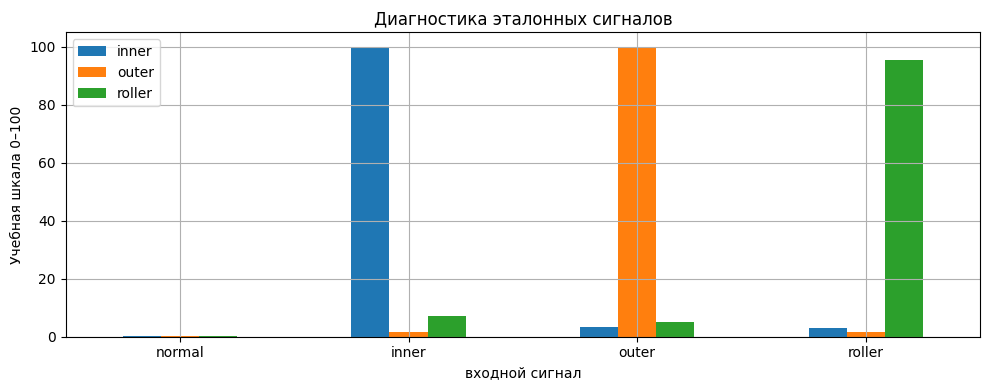

In [8]:
reference = pd.DataFrame({key: diagnose_signal(signal)
                          for key, signal in signals.items()}).T
reference.index.name = "входной сигнал"
display(reference)

ax = reference.plot.bar(figsize=(10, 4), rot=0,
                        title="Диагностика эталонных сигналов")
ax.set(ylabel="Учебная шкала 0–100", ylim=(0, 105))
plt.tight_layout(); plt.show()

## 7. Комбинированные дефекты

Проверим несколько synthetic signal mixtures. Целевые коэффициенты и прогнозы нужно
сравнивать в пунктах шкалы, а не как абсолютно точные физические измерения.

In [9]:
mixture_specs = {
    "8 / 7 / 12": (0.08, 0.07, 0.12),
    "50 / 50 / 50": (0.50, 0.50, 0.50),
    "80 / 10 / 60": (0.80, 0.10, 0.60),
}
rows = []
for name, (a_inner, a_outer, a_roller) in mixture_specs.items():
    mixture = (signals["normal"]
               + a_inner * (signals["inner"] - signals["normal"])
               + a_outer * (signals["outer"] - signals["normal"])
               + a_roller * (signals["roller"] - signals["normal"]))
    pred = diagnose_signal(mixture)
    rows.append({"смесь inner/outer/roller": name, **pred})
mixture_results = pd.DataFrame(rows).set_index("смесь inner/outer/roller")
mixture_results

,inner,outer,roller
смесь inner/outer/roller,,,
8 / 7 / 12,4.6,3.0,9.2
50 / 50 / 50,48.4,48.3,42.6
80 / 10 / 60,79.6,6.9,48.4


## 8. Десять новых WAV-записей

Для каждой записи проверяем sample rate, приводим PCM к float, делим на окна и получаем
три оценки. Это перенос на новые файлы, но ещё не независимая оценка точности без эталонных меток.

,inner,outer,roller
файл,,,
Подшипник_1.wav,0.2,0.1,0.4
Подшипник_2.wav,0.2,0.1,8.4
Подшипник_3.wav,0.9,0.9,76.4
Подшипник_4.wav,86.8,1.5,6.9
Подшипник_5.wav,21.6,53.6,45.7
Подшипник_6.wav,27.6,28.1,38.0
Подшипник_7.wav,8.8,10.5,76.3
Подшипник_8.wav,85.3,54.0,51.5
Подшипник_9.wav,49.3,44.3,46.2


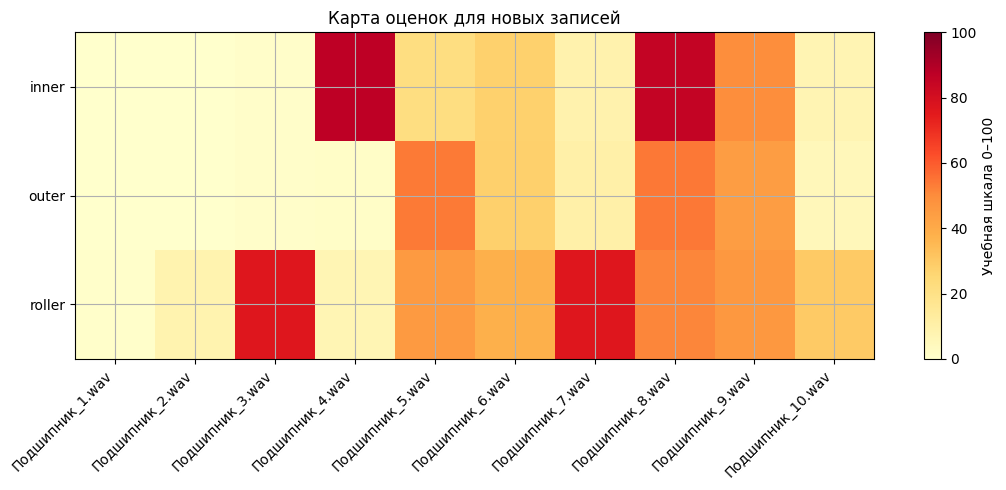

In [10]:
wav_rows = []
for path in sorted(DATA.glob("Подшипник_*.wav"),
                   key=lambda p: int(p.stem.split("_")[-1])):
    sample_rate, signal = read_wav(path)
    if sample_rate != FS:
        raise ValueError(f"{path.name}: ожидалось {FS} Гц, получено {sample_rate} Гц")
    prediction = diagnose_signal(signal, sample_rate)
    wav_rows.append({"файл": path.name, **prediction})

wav_results = pd.DataFrame(wav_rows).set_index("файл")
display(wav_results)

fig, ax = plt.subplots(figsize=(11, 5))
image = ax.imshow(wav_results.T, cmap="YlOrRd", vmin=0, vmax=100, aspect="auto")
ax.set(xticks=range(len(wav_results)), xticklabels=wav_results.index,
       yticks=range(3), yticklabels=wav_results.columns,
       title="Карта оценок для новых записей")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.colorbar(image, ax=ax, label="Учебная шкала 0–100")
plt.tight_layout(); plt.show()

## 9. Не скрываем разброс между окнами

Среднее число не показывает нестабильность. Квантили по окнам помогают отличить
устойчивый сигнал от записи, где дефект возникает только в части окон.

,inner,outer,roller
0.1,6.2,3.9,28.2
0.5,7.1,5.1,29.1
0.9,9.1,7.1,33.5


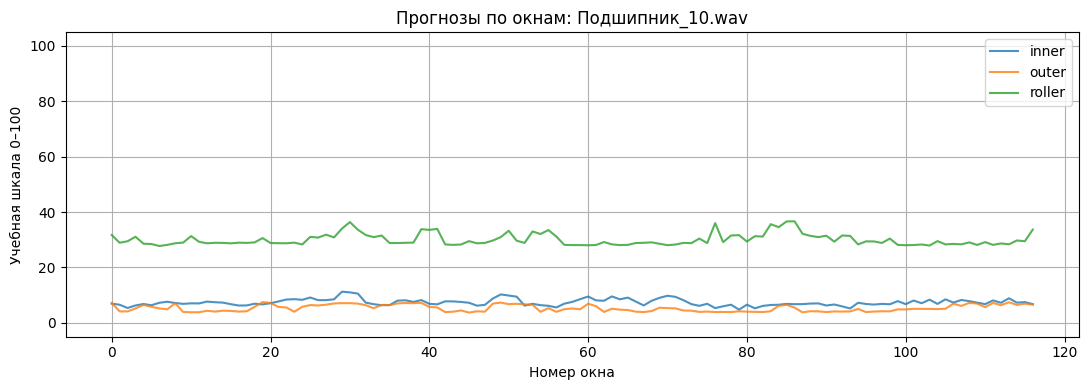

In [11]:
sample_rate, sample_signal = read_wav(DATA / "Подшипник_10.wav")
window_predictions = diagnose_windows(sample_signal, sample_rate)
display(window_predictions.quantile([0.1, 0.5, 0.9]).round(1))

ax = window_predictions.plot(figsize=(11, 4), alpha=0.8,
                             title="Прогнозы по окнам: Подшипник_10.wav")
ax.set(xlabel="Номер окна", ylabel="Учебная шкала 0–100", ylim=(-5, 105))
plt.tight_layout(); plt.show()

## 10. От числа к решению

Категории ниже — учебная иллюстрация. В реальной системе границы настраивают по цене
пропуска дефекта, цене ложной тревоги и данным эксплуатации.

In [12]:
decision_table = wav_results.copy()
for column in decision_table:
    decision_table[column] = decision_table[column].map(state_label)
decision_table

,inner,outer,roller
файл,,,
Подшипник_1.wav,идеальное,идеальное,идеальное
Подшипник_2.wav,идеальное,идеальное,идеальное
Подшипник_3.wav,идеальное,идеальное,критический износ
Подшипник_4.wav,критический износ,идеальное,идеальное
Подшипник_5.wav,средний износ,сильный износ,сильный износ
Подшипник_6.wav,средний износ,средний износ,средний износ
Подшипник_7.wav,идеальное,хорошее,критический износ
Подшипник_8.wav,критический износ,сильный износ,сильный износ
Подшипник_9.wav,сильный износ,сильный износ,сильный износ


## Вывод

Мы загрузили не только модели, но весь конвейер предобработки; проверили эталоны,
смеси и новые WAV-файлы; посмотрели не только средний прогноз, но и разброс по окнам.
Так модель превращается в воспроизводимый и проверяемый инженерный конвейер.